<a href="https://colab.research.google.com/github/meryllinoliveira/Projetos/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Célula 01 - Importações

In [40]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Carregar os dados

In [41]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "filmes"   # ex.: "livros"
NOME_TABELA_FATO = "visualizacoes"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
filmes -> 10300 linhas
visualizacoes -> 55000 linhas


Célula 3 - Conhecendo a tabela dimensão

In [42]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10300 linhas e 7 colunas (variáveis)


,filme_id,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,Segredo Vale,animação,1991,85,L,Pietra Brito
1,2,Distante Destino,animação,2002,155,14,Luiz Miguel da Conceição
2,3,Dourado Deserto,ação,1995,128,L,Joaquim da Mota
3,4,Sombra Caminho,comédia,2016,120,16,Milena Cavalcante
4,5,Escarlate Vale,romance,1992,101,L,Marina Pimenta


Célula 04 · Conhecendo a tabela fato

In [43]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False


Célula 05 · Tipos das colunas

In [44]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   visualizacao_id      55000 non-null  int64 
 1   filme_id             55000 non-null  int64 
 2   usuario_id           55000 non-null  int64 
 3   data_hora_inicio     55000 non-null  object
 4   tempo_assistido_min  55000 non-null  int64 
 5   dispositivo          55000 non-null  object
 6   concluido            55000 non-null  bool  
dtypes: bool(1), int64(4), object(2)
memory usage: 2.6+ MB


Célula 06 · Valores ausentes

In [45]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
visualizacao_id        0
filme_id               0
usuario_id             0
data_hora_inicio       0
tempo_assistido_min    0
dispositivo            0
concluido              0
dtype: int64


Célula 07 · Linhas duplicadas

In [46]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira

In [47]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "filme_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "filme_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


Célula 09 · Checar a coluna numérica

In [48]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "filme_id"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


Célula 10 · Medidas estatísticas

In [49]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,5298.11
Mediana,5291.00
Moda,10127.00
Desvio padrão,3034.68
Variância,9209274.80
Mínimo,1.00
Máximo,10300.00
Amplitude,10299.00


Média - mediana: 7.11


Célula 11 · Juntar a realidade com a dimensão

In [50]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


In [51]:
df_completo.head()

,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False,Silencioso Oceano 2252,ação,2006,108,18,Maria Laura Cassiano
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False,Eterno Horizonte 6588,terror,1988,128,14,Jade Rocha
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False,Sombra Vento 5799,drama,1997,84,10,Dr. Asafe Pires
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False,Fronteira Deserto 2255,ação,1995,183,12,Isabel Mendes
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False,Silencioso Oceano 8759,comédia,2004,168,10,Theo das Neves


Célula 12 · Comparar grupos por uma coluna da fato

In [52]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "dispositivo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
dispositivo,,,,
console,2734,5343.06,5361.0,2978.28
celular,16503,5311.02,5316.0,3033.69
smart_tv,21994,5302.36,5302.0,3032.98
tablet,5581,5288.13,5282.0,3047.65
computador,8188,5252.46,5190.5,3051.20


### Leitura por Dispositivo ###

- O grupo com a maior média é o console (com média de 5343,06). A mediana confirma essa tendência, pois o console também apresenta o maior valor mediano (5361,0) entre todos os dispositivos

- O grupo com o maior desvio padrão é o computador (com um desvio padrão de 3051,20), indicando que os seus valores estão um pouco mais espalhados/dispersos em relação à média do grupo.

- Os diferentes dispositivos (console, celular, smart_tv, tablet e computador) apresentam valores de média e mediana bastante próximos e equilibrados (variando em uma faixa muito estreita, entre 5252 e 5343). Isso indica que a distribuição da variável analisada (filme_id) é muito homogênea entre as categorias de dispositivos, ou seja, o tipo de aparelho utilizado não gera grandes distorções ou diferenças significativas no comportamento central dos dados da base.

Célula 13 · Comparar grupos por uma coluna da dimensão

In [53]:
COLUNA_GRUPO = "genero"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
genero,,,,
drama,10675,5527.95,5386.0,3205.22
ação,8708,5447.07,5423.5,3006.18
documentário,4111,5371.07,5791.0,3214.21
ficção científica,7340,5300.34,5438.0,3000.33
animação,5629,5294.46,5278.0,2963.11
romance,4893,5234.21,5093.0,2989.63
comédia,7966,5024.78,5227.0,2957.68
terror,5678,5023.99,4967.0,2815.24


Célula 14 · Regra do IQR

In [54]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -5298.50 a 16065.50
Outliers: 0 de 55000 valores
Maiores valores: [10300, 10300, 10300, 10300, 10300]
Menores valores: [1, 1, 1, 2, 2]


Célula 15 · Medidas com e sem os candidatos a outlier

In [55]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,5298.11,5298.11
Mediana,5291.00,5291.00
Desvio padrão,3034.68,3034.68


### Leitura e decisão registrada ###

1.   Item da lista
2.   Item da lista



1.   Item da lista
2.   Item da lista



- A regra do IQR marcou 0 outliers em um total de 55.000 valores, de modo que as medidas estatísticas com e sem os candidatos a outlier permaneceram idênticas (média de 5298.11, mediana de 5291.00 e desvio padrão de 3034.68)

-A decisão seria Manter, pois a base está íntegra e não há valores discrepantes extremos afetando a análise.

- Os valores ausentes Foram ignorados nos cálculos estatísticos (conforme o padrão adotado na Célula 06), preservando a integridade das demais observações.

Célula 16 · Assimetria (inclinação)

In [56]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: -0.04


Célula 17 · Percentis

In [57]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10    1063.0
0.25    2713.0
0.50    5291.0
0.75    8054.0
0.90    9429.0
Name: filme_id, dtype: float64


Célula 18 · Quantidade de valores por faixa

In [58]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
filme_id,
"(-9.299, 2060.8]",10701
"(2060.8, 4120.6]",10239
"(4120.6, 6180.4]",11518
"(6180.4, 8240.2]",9722
"(8240.2, 10300.0]",12820


###Leitura da distribuição dos valores ###

- A assimetria de -0.04 e indica que os dados possuem um formato bastante equilibrado e simétrico.

- Pelos percentis, observamos que 50% dos valores encontram-se abaixo de 5291.0, enquanto 75% estão abaixo de 8054.0.

- A divisão em faixas mostra que os registros se distribuem de maneira relativamente uniforme ao longo da escala, com uma leve concentração maior na faixa final (de 8240.2 a 10300.0, com 12.820 ocorrências).

- - A maioria dos valores fica entre 1063.0 (percentil de 10%) e 8054.0 (percentil de 75%), e poucos passam de 9429.0 (percentil de 90%).

## Recomendação ###

- Qual é a taxa de conclusão dos filmes entre os usuários?

- Média e mediana próximas (média de 5298.11 e mediana de 5291.00), o que demonstra uma distribuição muito simétrica (assimetria de -0.04) e equilibrada na base de dados.

- Desvio padrão de 3034.68 e a maioria dos valores concentrados entre o primeiro e o terceiro quartil (com 75% dos dados abaixo de 8054.0), indicando uma boa dispersão nas visualizações.

- Como os dados de visualização estão bem distribuídos e sem valores distorcidos, devemos focar as estratégias de engajamento nas faixas de filmes que possuem menor volume de conclusões para equilibrar a retenção dos usuários.

- Os dados são fictícios; nenhum outlier foi removido pois a base apresentou integridade total, e os valores ausentes foram ignorados nos cálculos estatísticos.

Célula 19 · Histograma

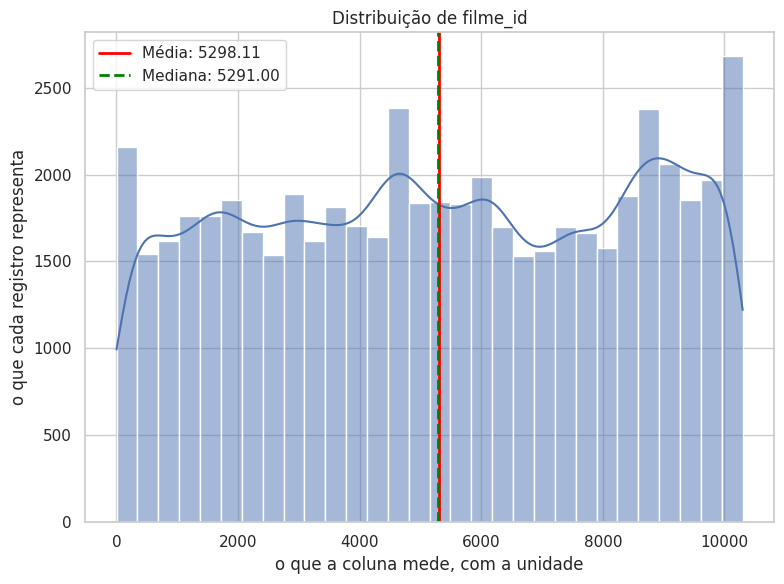

In [59]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O histograma exibe a distribuição uniforme e equilibrada dos IDs dos filmes assistidos ao longo da escala, evidenciando visualmente que a média (5298.11) e a mediana (5291.00) praticamente se sobrepõem no centro, confirmando a simetria dos dados.

Célula 20 · Boxplot

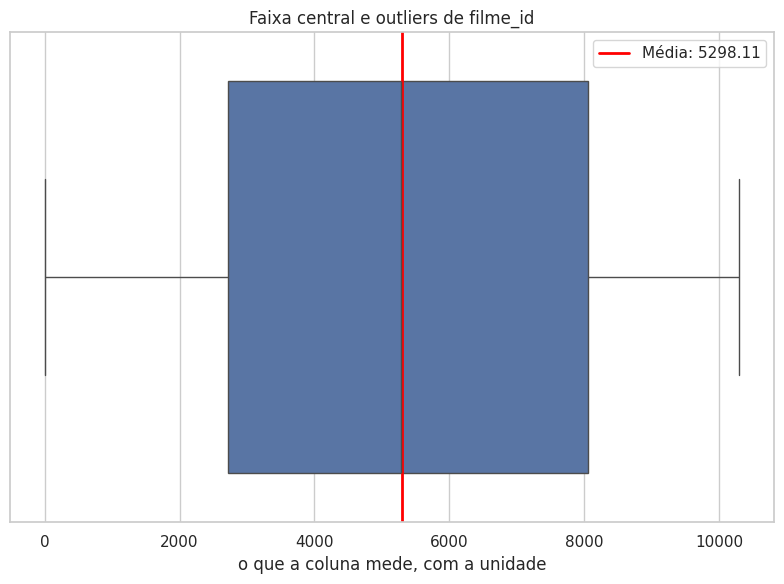

In [60]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O boxplot ilustra a faixa central (caixa azul concentrando de 25% a 75% dos dados) e a ausência de valores marcados para além dos limites, corroborando a inexistência de outliers extremos na base de dados analisada.